In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from PIL import Image
from sklearn.model_selection import train_test_split
import shutil

## define the dataset path

In [4]:
DATASET_PATH = Path(
    r"D:\py\Eye-Disease-Detection-system\dataset"
)

print(os.listdir(DATASET_PATH))

['cataract', 'conjunctivitis', 'labels.csv', 'normal', 'pterygium']


In [5]:
class_labels = {
    "normal": 0,
    "cataract": 1,
    "conjunctivitis": 2,
    "pterygium": 3
}

data = []

for class_name, label in class_labels.items():

    folder_path = DATASET_PATH / class_name

    for image_path in folder_path.rglob("*"):

        if image_path.suffix.lower() in [
            ".jpg", ".jpeg", ".png", ".bmp"
        ]:

            data.append({
                "image_path": str(image_path),
                "class_name": class_name,
                'label': label
            })

df = pd.DataFrame(data)

df = df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("Total images:", len(df))

df.head()

Total images: 4151


,image_path,class_name,label
0,D:\py\Eye-Disease-Detection-system\dataset\cat...,cataract,1
1,D:\py\Eye-Disease-Detection-system\dataset\pte...,pterygium,3
2,D:\py\Eye-Disease-Detection-system\dataset\con...,conjunctivitis,2
3,D:\py\Eye-Disease-Detection-system\dataset\cat...,cataract,1
4,D:\py\Eye-Disease-Detection-system\dataset\nor...,normal,0


In [6]:
print(df["class_name"].value_counts())

class_name
conjunctivitis    1293
cataract          1176
normal             882
pterygium          800
Name: count, dtype: int64


#### sample distribution

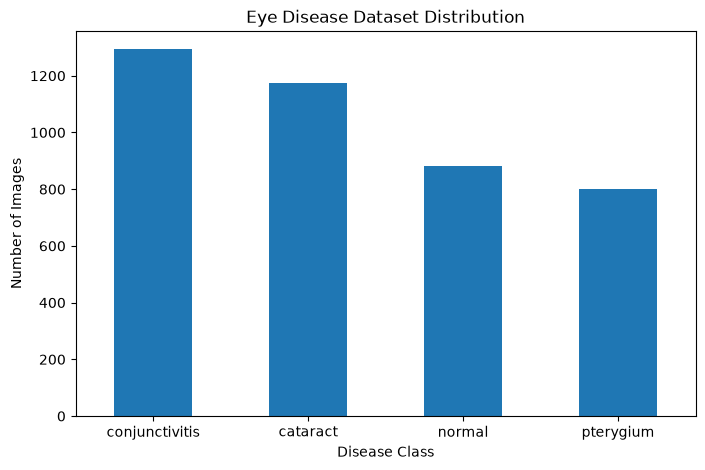

In [7]:
plt.figure(figsize=(8, 5))

df["class_name"].value_counts().plot(
    kind="bar"
)

plt.title("Eye Disease Dataset Distribution")
plt.xlabel("Disease Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)

plt.show()

### Display sample images


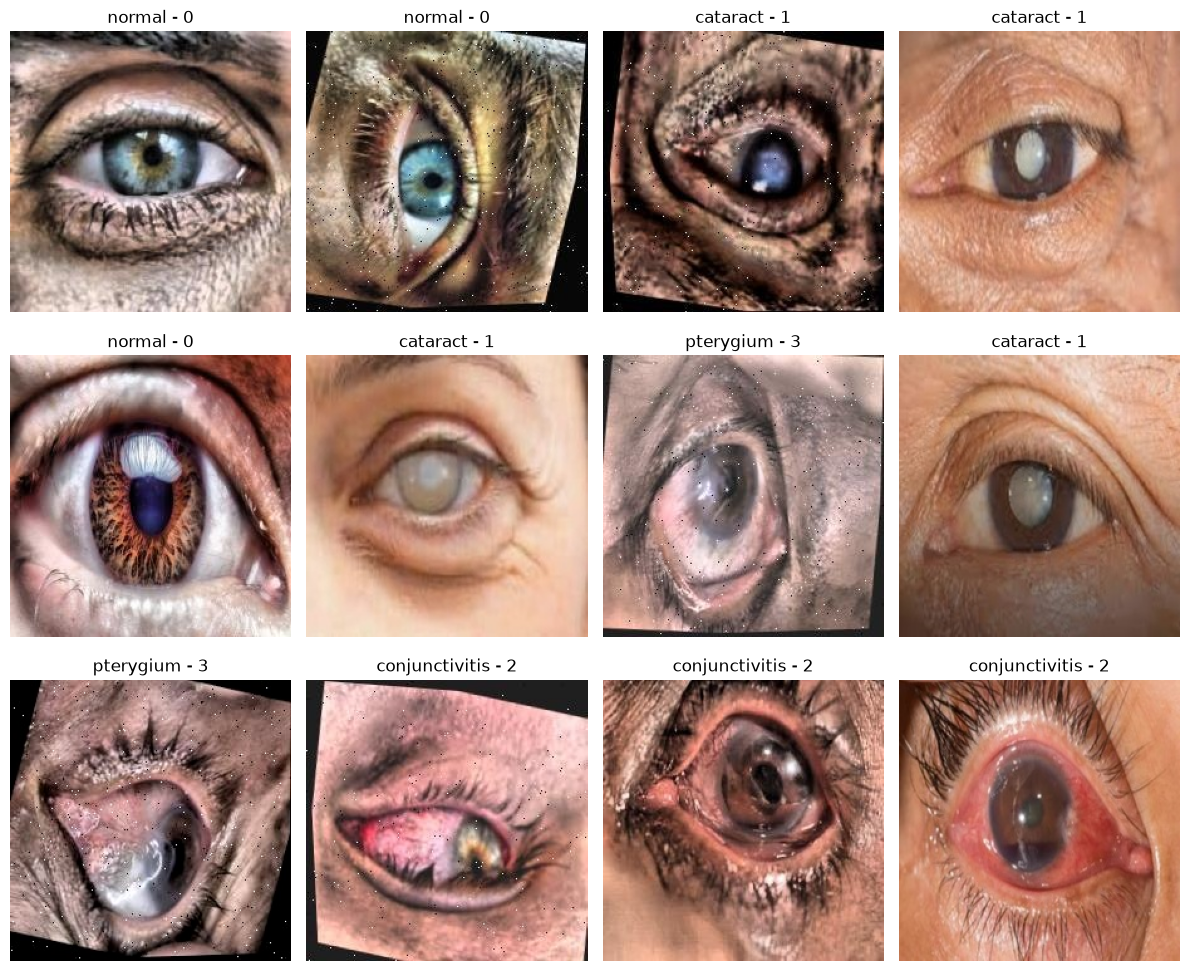

In [8]:
plt.figure(figsize=(12, 10))

samples = df.sample(
    min(12, len(df)),
    random_state=42
)

for i, (_, row) in enumerate(samples.iterrows()):

    image = Image.open(
        row["image_path"]
    ).convert("RGB")

    plt.subplot(3, 4, i + 1)

    plt.imshow(image)

    plt.title(
        f"{row['class_name']} - {row['label']}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [9]:
df.to_csv(
    DATASET_PATH / "labels.csv",
    index=False
)

print("Labels saved successfully!")

Labels saved successfully!


In [10]:
image_sample_path = df['image_path'][0]

with Image.open(image_sample_path) as img:
    width, height = img.size
    channels = len(img.getbands())

print(f"{width} x {height} pixels, {channels} chanels")


224 x 224 pixels, 3 chanels


In [11]:
# Dataset paths
OUTPUT_PATH = Path(r"D:\py\Eye-Disease-Detection-system\split_dataset")

CLASS_NAMES = [
    "normal",
    "cataract",
    "conjunctivitis",
    "pterygium"
]

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".gif"}

# Step 1: Collect image paths and labels
data = []

for class_name in CLASS_NAMES:
    class_folder = DATASET_PATH / class_name

    for image_path in class_folder.iterdir():
        if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
            data.append({
                "image_path": str(image_path),
                "class_name": class_name
            })

df = pd.DataFrame(data)

print("Original dataset distribution:")
print(df["class_name"].value_counts())

# Step 2: Stratified split (70% train, 30% temporary)
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["class_name"],
    random_state=42
)

# Step 3: Split temporary data into validation and testing
# 50% of 30% = 15% each
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["class_name"],
    random_state=42
)

# Step 4: Create folders and copy images
def save_split(dataframe, split_name):
    for class_name in CLASS_NAMES:
        destination = OUTPUT_PATH / split_name / class_name
        destination.mkdir(parents=True, exist_ok=True)

    for _, row in dataframe.iterrows():
        source = Path(row["image_path"])
        destination = OUTPUT_PATH / split_name / row["class_name"] / source.name

        shutil.copy2(source, destination)

# Prevent accidental mixing with an older split
if OUTPUT_PATH.exists():
    raise FileExistsError(
        f"{OUTPUT_PATH} already exists. "
        "Rename or remove it before generating a new split."
    )

save_split(train_df, "train")
save_split(val_df, "val")
save_split(test_df, "test")

# Step 5: Display distribution
distribution = pd.DataFrame({
    "Train": train_df["class_name"].value_counts(),
    "Validation": val_df["class_name"].value_counts(),
    "Test": test_df["class_name"].value_counts()
}).reindex(CLASS_NAMES)

distribution["Total"] = distribution.sum(axis=1)

print("\nStratified dataset distribution:")
print(distribution)

print("\nTotal training images:", len(train_df))
print("Total validation images:", len(val_df))
print("Total testing images:", len(test_df))

print("\nDataset splitting completed successfully!")


Original dataset distribution:
class_name
conjunctivitis    1293
cataract          1176
normal             882
pterygium          800
Name: count, dtype: int64

Stratified dataset distribution:
                Train  Validation  Test  Total
class_name                                    
normal            617         133   132    882
cataract          823         176   177   1176
conjunctivitis    905         194   194   1293
pterygium         560         120   120    800

Total training images: 2905
Total validation images: 623
Total testing images: 623

Dataset splitting completed successfully!
